# 2. Estimating preferences

Three ways to estimate partworths from the online ratings:
1. pooled OLS: one set of partworths for everyone
2. individual OLS: a separate regression for every respondent (20 ratings, 10 parameters)
3. hierarchical Bayes (HB): individual partworths shrunk toward the population mean

Price is coded from -0.5 ($120) to 0.5 ($180), so the price coefficient is the change in rating when moving from the cheapest to the most expensive bag, and the intercept is the rating of a $150 bag with all base levels.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_data, encode, to_long
from models import pooled_ols, individual_ols, hb, add_const, rmse, hit_rate

design, online, offline = load_data()
X = encode(design)
cols = list(X.columns)
names = ["const"] + cols
long = to_long(online, X)

## Pooled OLS

Standard errors are clustered by respondent, since each person gives 20 ratings.

In [3]:
pooled = pooled_ols(long, cols)
pd.DataFrame({"coef": pooled.params, "se": pooled.bse, "p": pooled.pvalues}).round(3)

,coef,se,p
const,2.051,0.096,0.0
price,-0.669,0.065,0.0
exterior_reflective,-0.314,0.071,0.0
exterior_colorful,-1.064,0.102,0.0
exterior_blue,-0.220,0.058,0.0
size_large,0.268,0.050,0.0
strap_pad_yes,0.510,0.050,0.0
pocket_yes,0.448,0.041,0.0
interior_file_divider,0.407,0.049,0.0
interior_laptop,0.619,0.065,0.0


## Individual OLS and HB

In [4]:
B_ols = individual_ols(online, X)
res = hb(online, X, seed=0)
B_hb = res["B"].mean(0)

/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:30: RuntimeWarning: divide by zero encountered in matmul
  ZR = R @ Z
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:30: RuntimeWarning: overflow encountered in matmul
  ZR = R @ Z
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:30: RuntimeWarning: invalid value encountered in matmul
  ZR = R @ Z
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:45: RuntimeWarning: divide by zero encountered in matmul
  mean = (ZR / s2 + Sinv @ mu) @ cov
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:45: RuntimeWarning: overflow encountered in matmul
  mean = (ZR / s2 + Sinv @ mu) @ cov
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:45: RuntimeWarning: invalid value encountered in matmul
  mean = (ZR / s2 + Sinv @ mu) @ cov
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:46: Runtime

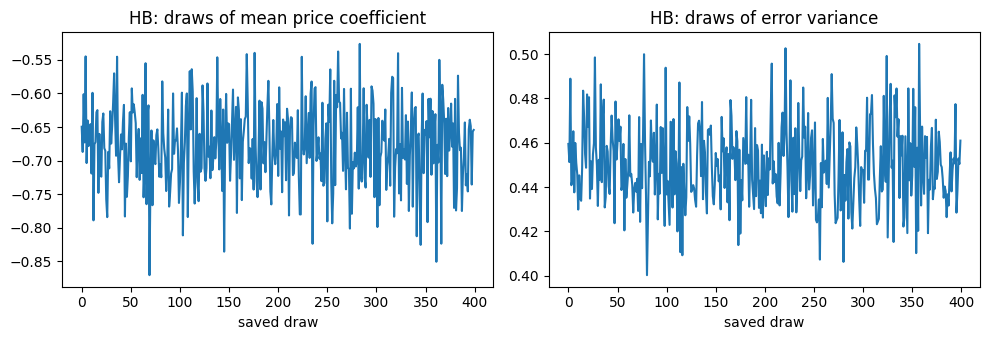

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(res["mu"][:, 1])
ax[0].set_title("HB: draws of mean price coefficient")
ax[0].set_xlabel("saved draw")
ax[1].plot(res["s2"])
ax[1].set_title("HB: draws of error variance")
ax[1].set_xlabel("saved draw")
plt.tight_layout()
plt.show()

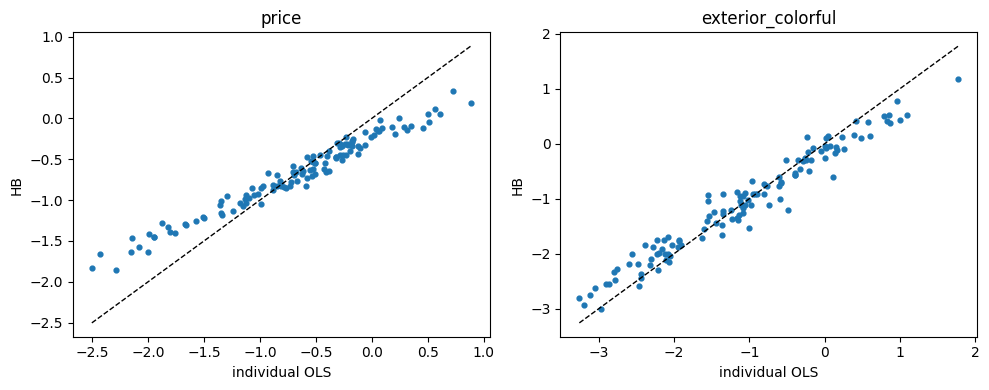

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for k, j in enumerate([names.index("price"), names.index("exterior_colorful")]):
    ax[k].scatter(B_ols[:, j], B_hb[:, j], s=12)
    lim = [min(B_ols[:, j].min(), B_hb[:, j].min()), max(B_ols[:, j].max(), B_hb[:, j].max())]
    ax[k].plot(lim, lim, "k--", lw=1)
    ax[k].set_xlabel("individual OLS")
    ax[k].set_ylabel("HB")
    ax[k].set_title(names[j])
plt.tight_layout()
plt.show()

HB pulls extreme individual estimates toward the mean (points are flatter than the 45 degree line). This is expected: with 20 ratings and 10 parameters, a lot of the spread in individual OLS estimates is noise.

## Which model predicts better?

For each split I hide 4 of the 20 bags for every respondent, estimate on the other 16 and predict the hidden ratings. I only use splits where the remaining 16 bags still identify all parameters. "Pooled + intercept" is pooled OLS plus a respondent-specific shift in the average rating.

Hit rate is a share of respondents for whom the bag with the highest predicted rating is one of their actually top-rated hidden bags.

In [8]:
rng = np.random.default_rng(1)
Z = add_const(X)
splits = []
while len(splits) < 10:
    test = np.sort(rng.choice(20, 4, replace=False))
    train = np.setdiff1d(np.arange(20), test)
    if np.linalg.matrix_rank(Z[train]) == Z.shape[1]:
        splits.append((train, test))

rows = []
for s, (train, test) in enumerate(splits):
    Rtr, Rte = online[:, train], online[:, test]
    Xtr, Xte = X.iloc[train], X.iloc[test]
    Zte = add_const(Xte)

    b_pool = np.linalg.lstsq(add_const(Xtr), Rtr.mean(0), rcond=None)[0]
    pred_pool = np.tile(Zte @ b_pool, (len(online), 1))
    shift = (Rtr - add_const(Xtr) @ b_pool).mean(1, keepdims=True)
    pred_shift = pred_pool + shift
    pred_ols = individual_ols(Rtr, Xtr) @ Zte.T
    pred_hb = hb(Rtr, Xtr, n_iter=4000, burn=1000, seed=s)["B"].mean(0) @ Zte.T

    for name, pred in [("pooled", pred_pool), ("pooled + intercept", pred_shift),
                       ("individual OLS", pred_ols), ("HB", pred_hb)]:
        rows.append({"split": s, "model": name, "rmse": rmse(pred, Rte), "hit rate": hit_rate(pred, Rte)})

cv = pd.DataFrame(rows)
table = cv.groupby("model", sort=False)[["rmse", "hit rate"]].agg(["mean", "sem"]).round(3)
table

/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:30: RuntimeWarning: divide by zero encountered in matmul
  ZR = R @ Z
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:30: RuntimeWarning: overflow encountered in matmul
  ZR = R @ Z
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:30: RuntimeWarning: invalid value encountered in matmul
  ZR = R @ Z
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:45: RuntimeWarning: divide by zero encountered in matmul
  mean = (ZR / s2 + Sinv @ mu) @ cov
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:45: RuntimeWarning: overflow encountered in matmul
  mean = (ZR / s2 + Sinv @ mu) @ cov
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:45: RuntimeWarning: invalid value encountered in matmul
  mean = (ZR / s2 + Sinv @ mu) @ cov
/Users/dorfm/Desktop/Учеба/segmentation-value/notebooks/../src/models.py:46: Runtime

rmse        hit rate       
                     mean    sem     mean    sem
model                                           
pooled              1.112  0.029    0.731  0.040
pooled + intercept  1.059  0.032    0.731  0.040
individual OLS      1.091  0.044    0.762  0.018
HB                  0.871  0.021    0.799  0.020

HB predicts hidden ratings best: lower RMSE than both pooled OLS and individual OLS, and the highest hit rate. Individual OLS is barely better than pooled OLS in RMSE because its estimates are so noisy. So there is real heterogeneity in the data, but it has to be estimated with shrinkage. I use HB partworths in the rest of the project.

## Preference heterogeneity (HB)

In [9]:
sd = np.sqrt(np.array([np.diag(S) for S in res["Sigma"]]).mean(0))
het = pd.DataFrame({
    "mean": res["mu"].mean(0),
    "sd across people": sd,
    "share with positive partworth": (B_hb > 0).mean(0),
}, index=names).round(2)
het

,mean,sd across people,share with positive partworth
const,2.04,0.90,1.00
price,-0.68,0.57,0.05
exterior_reflective,-0.31,0.57,0.22
exterior_colorful,-1.06,1.00,0.14
exterior_blue,-0.21,0.45,0.25
size_large,0.27,0.46,0.78
strap_pad_yes,0.51,0.47,0.93
pocket_yes,0.45,0.38,0.96
interior_file_divider,0.41,0.39,0.96
interior_laptop,0.62,0.59,0.93


Almost everyone dislikes higher prices and likes the functional features (strap pad, pocket, dividers, laptop compartment), but the strength of these preferences varies a lot: for most attributes the standard deviation across people is about as large as the mean. Exterior design is where people disagree most: on average the colorful exterior is the least liked, but it also has the largest spread. Size splits people: about 3/4 prefer the large bag.